# Milestone 2: Learned Image Compression on the Kodak Dataset
Project 30: Rate-Distortion Benchmarking Suite (Classical vs. Learned Image Codecs)

This notebook continues the Milestone 1 pipeline and runs the three pretrained CompressAI models on all 24 Kodak images at all available quality levels.

Models:
- Factorized Prior (bmshj2018_factorized), quality levels 1 to 8
- Scale Hyperprior (bmshj2018_hyperprior), quality levels 1 to 8
- Cheng2020 Anchor (cheng2020_anchor), quality levels 1 to 6

For every image we record the bitrate (bpp), PSNR, SSIM, MS-SSIM, encoding time and decoding time. The average results are then compared with the Kodak results published by CompressAI.

Steps to run:
1. Run section 1.1, then restart the session (Runtime, Restart session).
2. Select the first code cell of section 1.2 and choose Runtime, Run cell and below.
3. Results are saved to Google Drive after every image. If the session disconnects, run section 1.2 and below again and the finished runs will be skipped.

## 1.1 Installation of Required Libraries
Install CompressAI and the MS-SSIM library. Colab now uses Python 3.13, and CompressAI 1.2.8 asks for NumPy older than 2.0, which is not available for Python 3.13, so in that case CompressAI is installed without this restriction.

In [1]:
# ============================================================
# SECTION 1.1: INSTALLATION
# ============================================================
import sys
print("Python", sys.version.split()[0])

if sys.version_info >= (3, 13):
    !pip install -q pybind11 einops tomli torch-geometric pytorch-msssim
    !pip install -q --no-deps --no-build-isolation compressai==1.2.8
else:
    !pip install -q compressai==1.2.8 pytorch-msssim

print("Done. Restart the session before running the next cells.")

Python 3.13.18
  Preparing metadata (pyproject.toml) ... done
Done. Restart the session before running the next cells.


## 1.2 Library Imports and Environment Verification
Import the libraries and check that the installed NumPy version is the one loaded in the session.

In [1]:
# ============================================================
# SECTION 1.2: IMPORTS
# ============================================================
import os, io, json, time, random, hashlib, platform, urllib.request
from importlib.metadata import version as pkg_version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F
import compressai
from compressai.zoo import bmshj2018_factorized, bmshj2018_hyperprior, cheng2020_anchor
from pytorch_msssim import ssim, ms_ssim

# The session must be restarted after installation
assert np.__version__ == pkg_version("numpy"), (
    f"NumPy loaded {np.__version__} but installed {pkg_version('numpy')}. "
    "Restart the session and run again from section 1.2.")

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("CompressAI  :", compressai.__version__)
print("NumPy       :", np.__version__)
print("CPU threads :", torch.get_num_threads())

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Python      : 3.13.18
PyTorch     : 2.14.1+cpu
CompressAI  : 1.2.8
NumPy       : 2.4.6
CPU threads : 1


## 1.3 Experiment Configuration and Reproducibility
Define the random seed, the computing device, the models and quality levels, and the output folders.

All experiments run on the CPU so that every model is timed on the same hardware. CompressAI also notes that models with an autoregressive context model, such as Cheng2020, are not deterministic on GPU.

In [2]:
# ============================================================
# SECTION 1.3: EXPERIMENT CONFIGURATION
# ============================================================

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Device selection (CPU only)
DEVICE = torch.device("cpu")
torch.set_grad_enabled(False)

# Model configuration
MODELS = {
    "bmshj2018_factorized": {"fn": bmshj2018_factorized, "qualities": list(range(1, 9)), "label": "Factorized Prior"},
    "bmshj2018_hyperprior": {"fn": bmshj2018_hyperprior, "qualities": list(range(1, 9)), "label": "Scale Hyperprior"},
    "cheng2020_anchor":     {"fn": cheng2020_anchor,     "qualities": list(range(1, 7)), "label": "Cheng2020-Anchor"},
}
METRIC = "mse"

# Image padding
PAD_MULTIPLE = 64

# Bytes needed to store the latent shape for the decoder
HEADER_BYTES = 4

# Number of timing runs per image
TIMING_REPEATS = 1

# Images saved for visual comparison
SAVE_RECON_FOR = {"kodim01", "kodim23"}

# Output directories (Google Drive)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/DIP_Project/M2_learned")
except ImportError:
    OUT_DIR = Path("outputs/M2_learned")

# Dataset directory
DATA_DIR = Path("/content/datasets/kodak") if Path("/content").exists() else Path("datasets/kodak")

RECON_DIR = OUT_DIR / "reconstructions"
for d in (OUT_DIR, RECON_DIR, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

PER_IMAGE_CSV = OUT_DIR / "kodak_learned_per_image.csv"
print("Results folder:", OUT_DIR)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/DIP_Project/M2_learned


## 1.4 Kodak Dataset Download and Verification
Download the 24 Kodak images from the official website, check that all of them are RGB, and save the file list with SHA-256 checksums.

In [3]:
# ============================================================
# SECTION 1.4: KODAK DATASET
# ============================================================
KODAK_URL = "https://r0k.us/graphics/kodak/kodak/kodim{:02d}.png"

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

rows = []
for i in range(1, 25):
    path = DATA_DIR / f"kodim{i:02d}.png"
    if not path.exists():
        urllib.request.urlretrieve(KODAK_URL.format(i), path)
    with Image.open(path) as im:
        rows.append({"image": path.stem, "width": im.width, "height": im.height,
                     "mode": im.mode, "sha256": sha256(path)})

kodak_info = pd.DataFrame(rows)
assert len(kodak_info) == 24 and (kodak_info["mode"] == "RGB").all()
kodak_info.to_csv(OUT_DIR / "kodak_files_used.csv", index=False)

KODAK_FILES = sorted(DATA_DIR.glob("kodim*.png"))
print(len(KODAK_FILES), "Kodak images ready")
kodak_info.head()

24 Kodak images ready


,image,width,height,mode,sha256
0,kodim01,768,512,RGB,a56e27cbf5f843c048b6af1d6e090760e9c92fadba88b7...
1,kodim02,768,512,RGB,4f4b74a79237e311d72cad958237b5f7088d8bce1c8230...
2,kodim03,768,512,RGB,e25ca1ff2f0c0cb5fdfd5f9b0a0bb21ac4c3de3c84a67f...
3,kodim04,512,768,RGB,e3b946107c5d3441c022f678d0c3caf1e224d81b1604ba...
4,kodim05,768,512,RGB,10349e963c5c813d327852f82c1795fa4148d69fedffc4...


## 2.1 Preprocessing and Evaluation Functions
Functions used for every model:
- Image loading and conversion to a tensor with values between 0 and 1.
- Zero padding to a multiple of 64, split equally on both sides, and cropping back after decoding. Kodak images are 768x512, so no padding is needed here, but the same code will be used for Tecnick and CLIC.
- Rounding the reconstructed image to 8-bit values before evaluation, in the same way as the output of a classical codec.
- PSNR, SSIM and MS-SSIM computed on 8-bit RGB values. The same function should be used for JPEG, JPEG 2000, WebP and AVIF so that all codecs are measured in the same way.
- Bitstream size from the real entropy-coded output of the model.

In [4]:
# ============================================================
# SECTION 2.1: PREPROCESSING AND METRICS
# ============================================================

# Load an 8-bit RGB image as a tensor [1, 3, H, W] in [0, 1]
def load_image(path):
    arr = np.asarray(Image.open(path).convert("RGB"), dtype=np.uint8)
    return torch.from_numpy(arr).permute(2, 0, 1).float().div(255.0).unsqueeze(0), arr

# Symmetric zero padding to a multiple of 64
def pad_to_multiple(x, p=PAD_MULTIPLE):
    h, w = x.shape[2], x.shape[3]
    H, W = (h + p - 1) // p * p, (w + p - 1) // p * p
    left, top = (W - w) // 2, (H - h) // 2
    padding = (left, W - w - left, top, H - h - top)
    return F.pad(x, padding, mode="constant", value=0.0), padding

# Remove the padding after decoding
def crop(x, padding):
    left, right, top, bottom = padding
    return x[:, :, top:x.shape[2] - bottom, left:x.shape[3] - right]

# Convert the reconstruction to an 8-bit image
def to_uint8(x):
    return x.clamp(0, 1).mul(255).round().squeeze(0).permute(1, 2, 0).to(torch.uint8).numpy()

# PSNR, SSIM and MS-SSIM between two 8-bit RGB images
def evaluate_8bit(orig_u8, rec_u8):
    a = torch.from_numpy(orig_u8).permute(2, 0, 1).unsqueeze(0).double()
    b = torch.from_numpy(rec_u8).permute(2, 0, 1).unsqueeze(0).double()
    mse = torch.mean((a - b) ** 2).item()
    psnr = float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)
    return {"psnr": psnr,
            "ssim": ssim(a.float(), b.float(), data_range=255.0).item(),
            "ms_ssim": ms_ssim(a.float(), b.float(), data_range=255.0).item()}

# Total size of the compressed bitstream in bytes
def bitstream_bytes(strings):
    return sum(len(s) for level in strings for s in level)

# Check 1: an image compared with itself
_, demo = load_image(KODAK_FILES[0])
m = evaluate_8bit(demo, demo)
assert m["psnr"] == float("inf") and abs(m["ssim"] - 1) < 1e-6 and abs(m["ms_ssim"] - 1) < 1e-6

# Check 2: padding and cropping return the same image
t = torch.rand(1, 3, 500, 333)
tp, padding = pad_to_multiple(t)
assert tp.shape[2] % 64 == 0 and tp.shape[3] % 64 == 0 and torch.equal(crop(tp, padding), t)

print("Checks passed:", m)

/tmp/ipykernel_9884/2624440938.py:8: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(arr).permute(2, 0, 1).float().div(255.0).unsqueeze(0), arr


Checks passed: {'psnr': inf, 'ssim': 1.0, 'ms_ssim': 1.0}


## 2.2 Compression and Decompression of One Image
The image is padded, compressed to a bitstream and decompressed from the bitstream only. The encoding and decoding times are measured separately. The bitrate is computed with the original image size.

In [5]:
# ============================================================
# SECTION 2.2: ENCODE, DECODE AND EVALUATE ONE IMAGE
# ============================================================
def run_one(model, x, orig_u8, repeats=TIMING_REPEATS):
    h, w = orig_u8.shape[:2]
    x_pad, padding = pad_to_multiple(x)

    enc_times, dec_times = [], []
    for _ in range(repeats):
        t0 = time.perf_counter(); out = model.compress(x_pad); enc_times.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); rec = model.decompress(out["strings"], out["shape"]); dec_times.append(time.perf_counter() - t0)

    rec_u8 = to_uint8(crop(rec["x_hat"], padding))
    assert rec_u8.shape == orig_u8.shape

    payload = bitstream_bytes(out["strings"])
    result = {"payload_bytes": payload,
              "bpp_payload": 8 * payload / (h * w),
              "bpp_total": 8 * (payload + HEADER_BYTES) / (h * w),
              "enc_time_s": float(np.median(enc_times)),
              "dec_time_s": float(np.median(dec_times))}
    result.update(evaluate_8bit(orig_u8, rec_u8))
    return result, rec_u8

## 3.1 Running All Models on the Kodak Dataset
Each model is run at every quality level on the 24 images. Each result is added to the CSV file on Google Drive immediately, so the run can continue after a disconnection. One warm-up compression is done before timing each model and quality level, and it is not recorded.

In [6]:
# ============================================================
# SECTION 3.1: FULL KODAK EXPERIMENT
# ============================================================

# Runs that were already saved
done = set()
if PER_IMAGE_CSV.exists():
    prev = pd.read_csv(PER_IMAGE_CSV)
    done = set(zip(prev["model"], prev["quality"], prev["image"]))
    print(f"Resuming: {len(done)} runs already saved")

def append_row(row):
    pd.DataFrame([row]).to_csv(PER_IMAGE_CSV, mode="a", index=False, header=not PER_IMAGE_CSV.exists())

images = {p.stem: load_image(p) for p in KODAK_FILES}

for name, cfg in MODELS.items():
    for q in cfg["qualities"]:
        todo = [s for s in images if (name, q, s) not in done]
        if not todo:
            continue
        model = cfg["fn"](quality=q, metric=METRIC, pretrained=True, progress=False).eval().to(DEVICE)

        # Warm-up run (not recorded)
        run_one(model, *images[todo[0]], repeats=1)

        t_start = time.time()
        for stem in todo:
            x, orig_u8 = images[stem]
            res, rec_u8 = run_one(model, x, orig_u8)
            append_row({"model": name, "quality": q, "image": stem, **res})
            if stem in SAVE_RECON_FOR:
                Image.fromarray(rec_u8).save(RECON_DIR / f"{stem}_{name}_q{q}.png")
        print(f"{cfg['label']:18s} q={q}: {len(todo)} images in {time.time() - t_start:6.1f} s")

per_image = pd.read_csv(PER_IMAGE_CSV)
expected = sum(len(c["qualities"]) for c in MODELS.values()) * len(KODAK_FILES)
print(f"{len(per_image)} / {expected} runs saved")

Resuming: 528 runs already saved
528 / 528 runs saved


## 3.2 Average Results for Each Model and Quality Level
The bitrate and all quality metrics are averaged over the 24 images, as in the CompressAI evaluation. Times are reported as the median over the images. MS-SSIM is also given in dB using -10 log10(1 - MS-SSIM).

In [7]:
# ============================================================
# SECTION 3.2: AVERAGE RESULTS
# ============================================================
def summarize(per_image):
    g = per_image.groupby(["model", "quality"], sort=False)
    s = g.agg(n_images=("image", "count"),
              bpp=("bpp_payload", "mean"), bpp_total=("bpp_total", "mean"),
              psnr=("psnr", "mean"), ssim=("ssim", "mean"), ms_ssim=("ms_ssim", "mean"),
              enc_time_s=("enc_time_s", "median"), dec_time_s=("dec_time_s", "median")).reset_index()
    s["ms_ssim_db"] = -10 * np.log10(1 - s["ms_ssim"])
    return s

summary = summarize(per_image)
summary.to_csv(OUT_DIR / "kodak_learned_summary.csv", index=False)
summary.round(4)

,model,quality,n_images,bpp,bpp_total,psnr,ssim,ms_ssim,enc_time_s,dec_time_s,ms_ssim_db
0,bmshj2018_factorized,1,24,0.1226,0.1227,26.9057,0.7231,0.9099,0.8500,1.1657,10.4530
1,bmshj2018_factorized,2,24,0.1885,0.1886,28.2137,0.7709,0.9360,0.8601,1.1927,11.9357
2,bmshj2018_factorized,3,24,0.2878,0.2879,29.6110,0.8181,0.9554,0.8662,1.1824,13.5053
3,bmshj2018_factorized,4,24,0.4404,0.4405,31.2685,0.8652,0.9703,0.8642,1.1760,15.2682
4,bmshj2018_factorized,5,24,0.6481,0.6482,32.9437,0.9022,0.9806,0.8763,1.2099,17.1119
5,bmshj2018_factorized,6,24,0.9670,0.9671,35.3597,0.9351,0.9878,1.7540,2.3884,19.1343
6,bmshj2018_factorized,7,24,1.3512,1.3512,37.3647,0.9552,0.9921,1.7529,2.2335,21.0331
7,bmshj2018_factorized,8,24,1.8333,1.8334,39.5686,0.9696,0.9950,1.7257,2.2063,23.0308
8,bmshj2018_hyperprior,1,24,0.1313,0.1314,27.5780,0.7437,0.9173,0.9555,1.2655,10.8241
9,bmshj2018_hyperprior,2,24,0.2089,0.2090,29.1916,0.7953,0.9420,0.9503,1.2397,12.3644


## 3.3 Comparison with the Published CompressAI Results
CompressAI publishes Kodak results for the same pretrained models on CPU. Our average results at each quality level should be very close to these values. A large difference would mean a problem in our pipeline.

In [8]:
# ============================================================
# SECTION 3.3: COMPARISON WITH COMPRESSAI RESULTS
# ============================================================
REF_URL = "https://raw.githubusercontent.com/InterDigitalInc/CompressAI/master/results/image/kodak/{}.json"
REF_FILES = {"bmshj2018_factorized": "compressai-bmshj2018-factorized_mse_cpu",
             "bmshj2018_hyperprior": "compressai-bmshj2018-hyperprior_mse_cpu",
             "cheng2020_anchor":     "compressai-cheng2020-anchor_mse_cpu",
             "jpeg":                 "jpeg"}

def load_reference(key):
    with urllib.request.urlopen(REF_URL.format(REF_FILES[key])) as r:
        res = json.load(r)["results"]
    return pd.DataFrame({"bpp": res["bpp"],
                         "psnr": res.get("psnr-rgb", res.get("psnr")),
                         "ms_ssim": res.get("ms-ssim-rgb", res.get("ms-ssim"))})

refs = {k: load_reference(k) for k in REF_FILES}

def compare_with_reference(summary, refs):
    rows = []
    for name in MODELS:
        ours = summary[summary["model"] == name].sort_values("quality").reset_index(drop=True)
        ref = refs[name]
        for i, r in ours.iterrows():
            if i >= len(ref):
                break
            rows.append({"model": name, "quality": int(r["quality"]),
                         "bpp_ours": r["bpp"], "bpp_ref": ref.loc[i, "bpp"],
                         "bpp_diff_%": 100 * (r["bpp"] - ref.loc[i, "bpp"]) / ref.loc[i, "bpp"],
                         "psnr_ours": r["psnr"], "psnr_ref": ref.loc[i, "psnr"],
                         "psnr_diff_dB": r["psnr"] - ref.loc[i, "psnr"],
                         "ms_ssim_ours": r["ms_ssim"], "ms_ssim_ref": ref.loc[i, "ms_ssim"]})
    return pd.DataFrame(rows)

check = compare_with_reference(summary, refs)
check.to_csv(OUT_DIR / "kodak_vs_compressai_reference.csv", index=False)

# Points within 0.1 dB PSNR and 2% bpp of the published results
ok = (check["psnr_diff_dB"].abs() <= 0.1) & (check["bpp_diff_%"].abs() <= 2)
print(f"{ok.sum()} / {len(check)} operating points within 0.1 dB and 2 % bpp of CompressAI's results")
if not ok.all():
    print("Check these points:"); display(check[~ok].round(4))
check.round(4)

22 / 22 operating points within 0.1 dB and 2 % bpp of CompressAI's results


,model,quality,bpp_ours,bpp_ref,bpp_diff_%,psnr_ours,psnr_ref,psnr_diff_dB,ms_ssim_ours,ms_ssim_ref
0,bmshj2018_factorized,1,0.1226,0.1226,-0.0000,26.9057,26.9088,-0.0031,0.9099,0.9100
1,bmshj2018_factorized,2,0.1885,0.1885,-0.0000,28.2137,28.2179,-0.0043,0.9360,0.9360
2,bmshj2018_factorized,3,0.2878,0.2878,0.0000,29.6110,29.6169,-0.0059,0.9554,0.9555
3,bmshj2018_factorized,4,0.4404,0.4404,-0.0000,31.2685,31.2771,-0.0086,0.9703,0.9704
4,bmshj2018_factorized,5,0.6481,0.6481,0.0005,32.9437,32.9561,-0.0125,0.9806,0.9806
5,bmshj2018_factorized,6,0.9670,0.9670,0.0000,35.3597,35.3810,-0.0213,0.9878,0.9879
6,bmshj2018_factorized,7,1.3512,1.3512,-0.0003,37.3647,37.3969,-0.0322,0.9921,0.9922
7,bmshj2018_factorized,8,1.8333,1.8333,-0.0000,39.5686,39.6213,-0.0527,0.9950,0.9951
8,bmshj2018_hyperprior,1,0.1313,0.1313,0.0000,27.5780,27.5815,-0.0035,0.9173,0.9174
9,bmshj2018_hyperprior,2,0.2089,0.2089,-0.0000,29.1916,29.1967,-0.0051,0.9420,0.9421


## 3.4 Rate-Distortion Curves
PSNR and MS-SSIM against bpp for the three models. Our results are shown with solid lines and the CompressAI results with dashed lines. The JPEG curve published by CompressAI is added only as a reference.

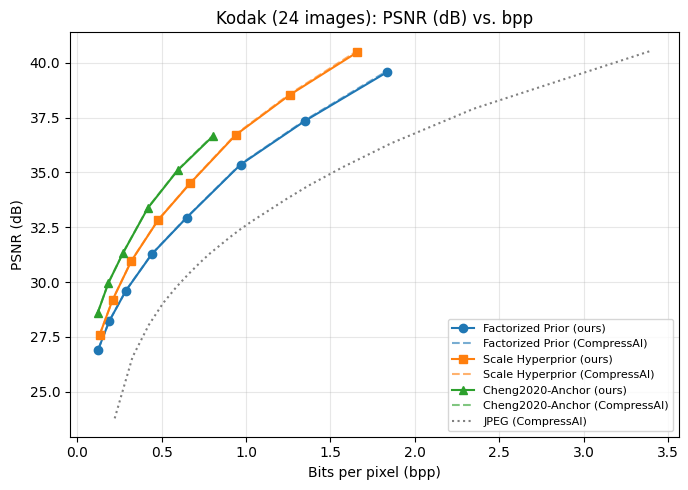

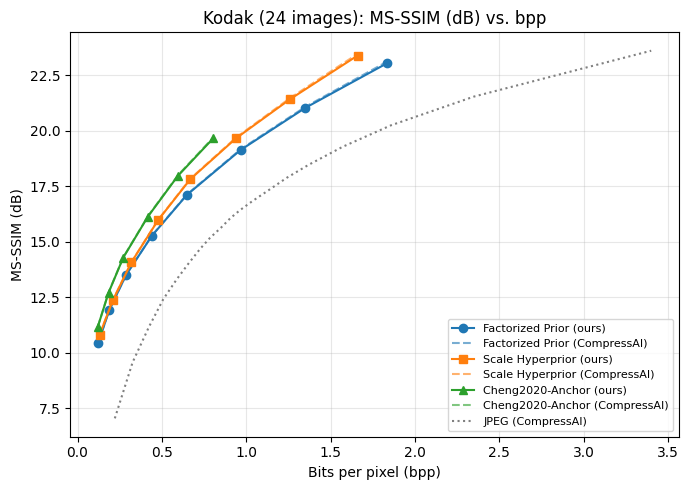

In [9]:
# ============================================================
# SECTION 3.4: RATE-DISTORTION CURVES
# ============================================================
STYLE = {"bmshj2018_factorized": ("tab:blue", "o"),
         "bmshj2018_hyperprior": ("tab:orange", "s"),
         "cheng2020_anchor":     ("tab:green", "^")}

def plot_rd(summary, refs, metric, ylabel, filename):
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, cfg in MODELS.items():
        color, marker = STYLE[name]
        s = summary[summary["model"] == name].sort_values("bpp")
        ax.plot(s["bpp"], s[metric], marker=marker, color=color, label=f"{cfg['label']} (ours)")
        ref = refs[name]
        y = ref[metric] if metric != "ms_ssim_db" else -10 * np.log10(1 - ref["ms_ssim"])
        ax.plot(ref["bpp"], y, ls="--", color=color, alpha=0.6, label=f"{cfg['label']} (CompressAI)")
    jpeg = refs["jpeg"]
    yj = jpeg[metric] if metric != "ms_ssim_db" else -10 * np.log10(1 - jpeg["ms_ssim"])
    ax.plot(jpeg["bpp"], yj, ls=":", color="gray", label="JPEG (CompressAI)")
    ax.set_xlabel("Bits per pixel (bpp)"); ax.set_ylabel(ylabel)
    ax.set_title(f"Kodak (24 images): {ylabel} vs. bpp"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUT_DIR / filename, dpi=200); plt.show()

plot_rd(summary, refs, "psnr", "PSNR (dB)", "rd_kodak_psnr.png")
plot_rd(summary, refs, "ms_ssim_db", "MS-SSIM (dB)", "rd_kodak_msssim_db.png")

## 3.5 Encoding and Decoding Time
Median encoding and decoding time per image for each model and quality level.

In [10]:
# ============================================================
# SECTION 3.5: TIMING TABLE
# ============================================================
timing = summary.pivot_table(index="quality", columns="model", values=["enc_time_s", "dec_time_s"]).round(2)
timing.to_csv(OUT_DIR / "kodak_learned_timing.csv")
timing

dec_time_s                                        \
model   bmshj2018_factorized bmshj2018_hyperprior cheng2020_anchor   
quality                                                              
1                       1.17                 1.27            17.17   
2                       1.19                 1.24            17.10   
3                       1.18                 1.23            17.23   
4                       1.18                 1.23            25.02   
5                       1.21                 1.23            25.48   
6                       2.39                 2.48            24.96   
7                       2.23                 2.43              NaN   
8                       2.21                 2.33              NaN   

                  enc_time_s                                        
model   bmshj2018_factorized bmshj2018_hyperprior cheng2020_anchor  
quality                                                             
1                       0.85                 0.96             7.44  
2                       0.86                 0.95             6.79  
3                       0.87                 0.96             7.36  
4                       0.86                 0.94            13.60  
5                       0.88                 0.95            13.83  
6                       1.75                 1.87            13.49  
7                       1.75                 1.87              NaN  
8                       1.73                 1.85              NaN

## 3.6 Environment and Requirements
Save the library versions and the requirements file for reproducibility.

In [11]:
# ============================================================
# SECTION 3.6: ENVIRONMENT AND REQUIREMENTS
# ============================================================
env = pd.DataFrame([{"python": platform.python_version(), "torch": torch.__version__,
                     "compressai": compressai.__version__, "numpy": np.__version__,
                     "pytorch_msssim": pkg_version("pytorch-msssim"), "cpu_threads": torch.get_num_threads(),
                     "processor": platform.processor() or platform.machine(), "seed": SEED,
                     "timing_repeats": TIMING_REPEATS}])
env.to_csv(OUT_DIR / "environment_m2.csv", index=False)

# Full list of installed packages
!pip freeze > "{OUT_DIR}/requirements_m2_full.txt"

# Main packages with fixed versions
pinned = [f"compressai=={compressai.__version__}", f"torch=={torch.__version__.split('+')[0]}",
          f"numpy=={np.__version__}", f"pandas=={pd.__version__}", f"pillow=={pkg_version('pillow')}",
          f"matplotlib=={pkg_version('matplotlib')}", f"pytorch-msssim=={pkg_version('pytorch-msssim')}"]
(OUT_DIR / "requirements.txt").write_text("\n".join(pinned) + "\n")
print((OUT_DIR / "requirements.txt").read_text())
env

compressai==1.2.8
torch==2.14.1
numpy==2.4.6
pandas==2.2.3
pillow==11.3.0
matplotlib==3.10.0
pytorch-msssim==1.0.0



,python,torch,compressai,numpy,pytorch_msssim,cpu_threads,processor,seed,timing_repeats
0,3.13.18,2.14.1+cpu,1.2.8,2.4.6,1.0.0,1,x86_64,42,1


## 3.7 Files to Upload to the GitHub Repository
- This notebook: notebooks/M2_StudentB_Learned_Codecs.ipynb
- kodak_learned_per_image.csv, kodak_learned_summary.csv, kodak_vs_compressai_reference.csv, kodak_learned_timing.csv: results/M2_learned/
- rd_kodak_psnr.png and rd_kodak_msssim_db.png: results/M2_learned/
- reconstructions folder: results/M2_learned/reconstructions/
- environment_m2.csv and kodak_files_used.csv: reports/
- requirements.txt: repository root

The file kodak_learned_summary.csv is shared with Student C for the comparison with the classical codecs, together with the evaluate_8bit function from section 2.1.